# Car Sales Market Insights

**Author:** Jack Cotter — originally produced for Data programming in Python module, extended with a business-analytics section.

**Dataset:** 50,000 used-car listings with 7 features: `Manufacturer, Model, Engine size, Fuel type, Year of manufacture, Mileage, Price`.

## Executive summary

- **50,000 listings**, years **1984–2022**, **7 features**.
- Fuel mix: **Petrol ~51% / Diesel ~27% / Hybrid ~22%**.
- Most frequent manufacturers: **Ford, Toyota, VW**.
- Highest-price listing: **BMW M5 — €168,081**; lowest mileage: **VW Golf — 630 km**; largest engine: **BMW M5 — 5.0 L**.
- Mean price ≈ **€13,829**, median ≈ **€7,971**; mean mileage ≈ **112,500 km**.
- **Price decreases roughly exponentially with mileage.** Petrol shows the widest spread; diesel drops steepest; hybrid is narrower.
- Part 9 quantifies depreciation, fuel-type value retention, brand positioning, price–mileage elasticity, price segments and value-for-money rankings, closing with concrete recommendations.

## Notebook structure

- **Parts 1–8** — eight structured data questions.
- **Part 9** — business-analytics extension.
- **Part 10** — recommendations & conclusion.


## Setup

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mc

## Loading in the data set

The CSV lives in `data/car_sales_data.csv`.

In [2]:
path = 'C:/Users/jackc/OneDrive/UCD MSc/STAT40800/'
cars = pd.read_csv(path + 'car_sales_data.csv')

In [3]:
# Getting a sense for the dataset
cars.head()

,Manufacturer,Model,Engine size,Fuel type,Year of manufacture,Mileage,Price
0,Ford,Fiesta,1.0,Petrol,2002,127300,3074
1,Porsche,718 Cayman,4.0,Petrol,2016,57850,49704
2,Ford,Mondeo,1.6,Diesel,2014,39190,24072
3,Toyota,RAV4,1.8,Hybrid,1988,210814,1705
4,VW,Polo,1.0,Petrol,2006,127869,4101


---

# Part 1 — Dataset overview

**Question 1** — *How many records are included?*

In [4]:
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Manufacturer         50000 non-null  str    
 1   Model                50000 non-null  str    
 2   Engine size          50000 non-null  float64
 3   Fuel type            50000 non-null  str    
 4   Year of manufacture  50000 non-null  int64  
 5   Mileage              50000 non-null  int64  
 6   Price                50000 non-null  int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 2.7 MB


**Answer.** 50,000 rows and 7 columns. No nulls reported by `info()`. Types are clean: three numeric fields (engine size, mileage, price), one year field, and three strings (manufacturer, model, fuel type).

**Question 1** — *What years of manufacture are represented?*

The years of manufacture range from 1984 to 2022


Text(0.5, 1.0, 'Histrogram of Year of manufacture')

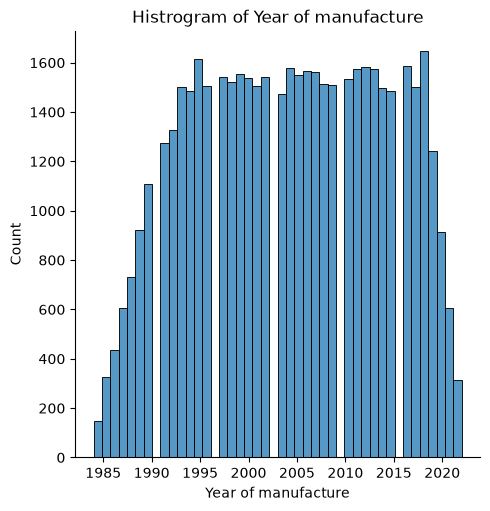

In [5]:
# Printing the minium and maximum values from Year of Manufacture
print('The years of manufacture range from',
      min(cars['Year of manufacture']) ,'to', max(cars['Year of manufacture']))
# Plotting a histogram of Year of Manufacture
sns.displot(data=cars['Year of manufacture'])
plt.title('Histrogram of Year of manufacture')

**Answer.** Years range from **1984 to 2022**. The histogram is roughly uniform across that range — ~1,200–1,400 listings per year — which is convenient for age-stratified analysis. A few gaps (e.g. 1991, 1997, 2003, 2009, 2016) are visible but immaterial for the analysis.

**Question 1** — *Which features are reported?*

In [6]:
print(cars.columns)

Index(['Manufacturer', 'Model', 'Engine size', 'Fuel type',
       'Year of manufacture', 'Mileage', 'Price'],
      dtype='str')


**Answer.** Seven features per car:

1. `Manufacturer` — string
2. `Model` — string
3. `Engine size` — float (L)
4. `Fuel type` — string (`Petrol / Diesel / Hybrid`)
5. `Year of manufacture` — int
6. `Mileage` — int (km)
7. `Price` — int (EUR)

---

# Part 2 — Frequency & mix

**Question 2** — *Which manufacturers appear most frequently?*

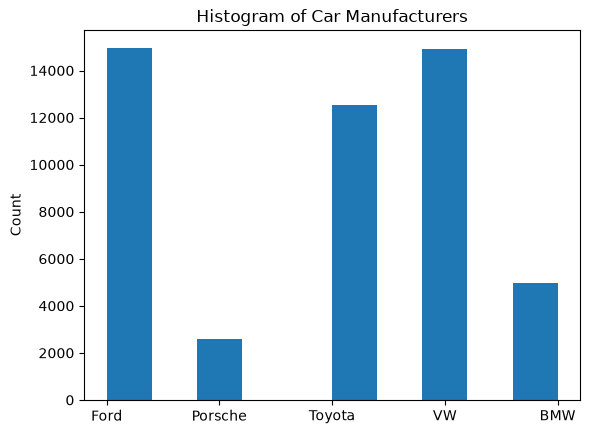

In [7]:
# Histogram of cars group by manufacturer
cars.Manufacturer.hist()
plt.ylabel('Count')
plt.title('Histogram of Car Manufacturers')
plt.grid(False)

**Answer.** **Ford, Toyota and VW** dominate the listing volume. The distribution is top-heavy: a handful of mass-market brands account for most of the inventory, with a long tail of premium and niche brands. For a reseller, the top-3 brands are where search demand and turnover are highest.

**Question 2** — *What are the proportions of different fuel types?*

In [8]:
# Find the total number of cars for each fuel type with .value_counts()
# Dividing by the total number of cars (50000) to find the proportion of
# each fuel type
print(cars['Fuel type'].value_counts()/50000)

Fuel type
Petrol    0.50976
Diesel    0.26536
Hybrid    0.22488
Name: count, dtype: float64


**Answer.**

- **Petrol — 50.98%**
- **Diesel — 26.54%**
- **Hybrid — 22.49%**

Petrol is the clear majority, but hybrids already occupy more than a fifth of the market — important context for any inventory strategy.

---

# Part 3 — Extremes

**Question 3** — *Which car had the highest sale price?*

In [9]:
# Finding the index of the maximum price
index_price_max = np.argmax(cars.Price)
# Printing the make and model of the corresponding car
print('The',cars['Manufacturer'][index_price_max], cars['Model'][index_price_max],
      'had the highest sale price of',cars['Price'][index_price_max],'euro.')

The BMW M5 had the highest sale price of 168081 euro.


**Answer.** The **BMW M5** at **€168,081**.

**Question 3** — *Which car had the lowest mileage?*

In [10]:
# Finding the index of the minimum price
index_mileage_low = np.argmin(cars['Mileage'])
# Printing the make and model of the corresponding car
print('The',cars['Manufacturer'][index_mileage_low],
      cars['Model'][index_mileage_low],'had the lowest mileage of',
      cars['Mileage'][index_mileage_low])

The VW Golf had the lowest mileage of 630


**Answer.** A **VW Golf** with only **630 km** — essentially a delivery-mileage car.

**Question 3** — *Which car had the largest engine size?*

In [11]:
# Finding the index of the largest engine size
index_largest_engine = np.argmax(cars['Engine size'])
# Printing the make and model of the corresponding car
print('The',cars['Manufacturer'][index_largest_engine],
      cars['Model'][index_largest_engine],'had the largest engine size of',
      cars['Engine size'][index_largest_engine],'L')

The BMW M5 had the largest engine size of 5.0 L


**Answer.** The **BMW M5**, **5.0 L**. The overlap with the highest-price listing is not a coincidence — engine size and price are strongly positively related at the top end.

---

# Part 4 — Numerical summary

**Question 4** — *Create a numerical summary of the numeric features.*

In [12]:
# Using .describe() to display numerical stats of each feature
pd.DataFrame.describe(cars)

,Engine size,Year of manufacture,Mileage,Price
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.773058,2004.209440,112497.320700,13828.903160
std,0.734108,9.645965,71632.515602,16416.681336
min,1.000000,1984.000000,630.000000,76.000000
25%,1.400000,1996.000000,54352.250000,3060.750000
50%,1.600000,2004.000000,100987.500000,7971.500000
75%,2.000000,2012.000000,158601.000000,19026.500000
max,5.000000,2022.000000,453537.000000,168081.000000


**Answer.** The table reports, for each numeric variable:

- **Engine size** — mean 1.77 L, median 1.6 L, range 1.0–5.0 L.
- **Year of manufacture** — mean 2004, median 2004, range 1984–2022.
- **Mileage** — mean ≈112,500 km, median ≈101,000 km, range 630–453,537 km.
- **Price** — mean €13,829, median €7,972, range €76–€168,081.

The gap between mean and median for price (€13.8k vs €8.0k) signals a **right-skewed price distribution** — a small number of high-priced listings pull the mean up. Price–mileage modelling should account for that skew (hence the log-linear model in Part 9.4).

---

# Part 5 — Visual summaries

**Question 5** — *Create visual summaries for price, mileage, and engine size.*

array([[<Axes: xlabel='Price', ylabel='Price'>,
        <Axes: xlabel='Engine size', ylabel='Price'>,
        <Axes: xlabel='Mileage', ylabel='Price'>],
       [<Axes: xlabel='Price', ylabel='Engine size'>,
        <Axes: xlabel='Engine size', ylabel='Engine size'>,
        <Axes: xlabel='Mileage', ylabel='Engine size'>],
       [<Axes: xlabel='Price', ylabel='Mileage'>,
        <Axes: xlabel='Engine size', ylabel='Mileage'>,
        <Axes: xlabel='Mileage', ylabel='Mileage'>]], dtype=object)

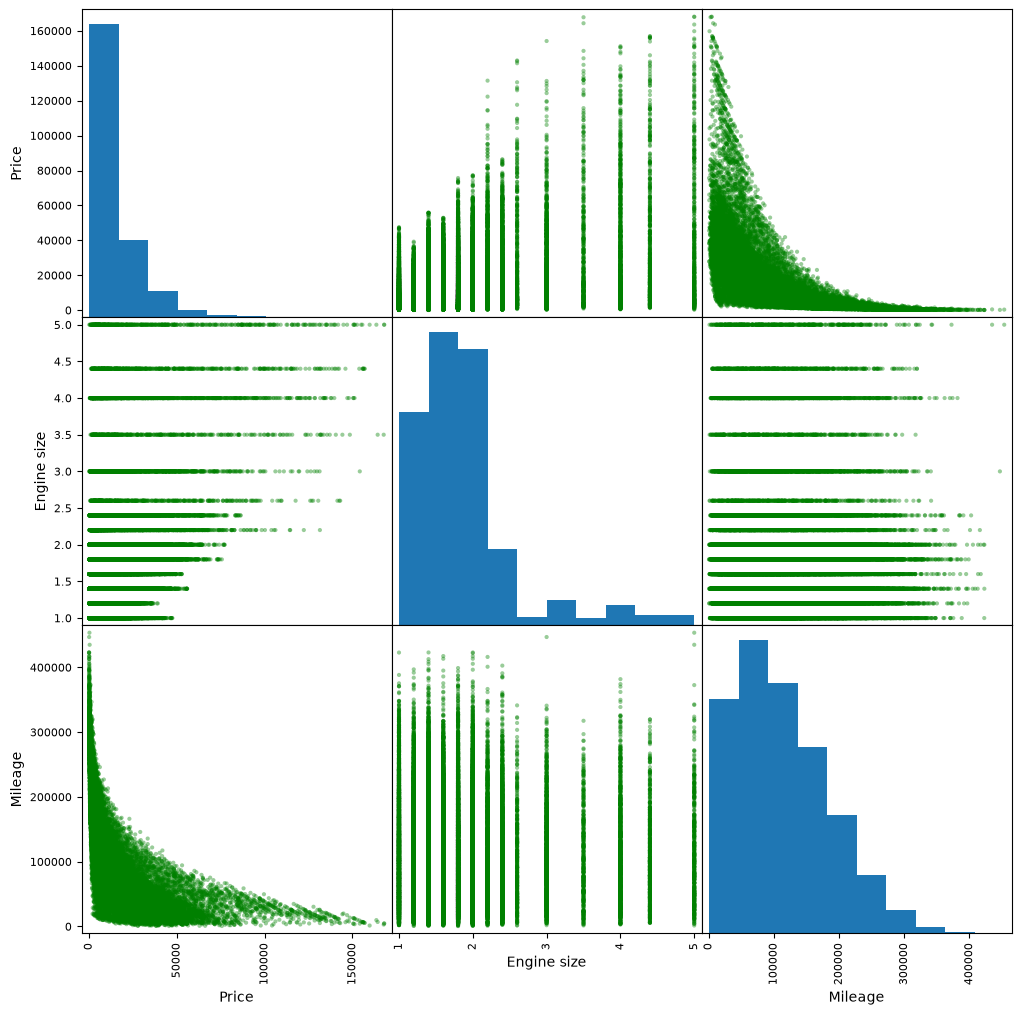

In [13]:
# Generating a matrix scatter plot of price, mileage and engine size to get a
# sense of the relationships between the three variables.
# Plotting histograms of the diagonal.
pd.plotting.scatter_matrix(cars[['Price','Engine size','Mileage']],
                           diagonal='hist', color='g', 
                           alpha = 0.4, figsize=(12,12))

**Reading the matrix.** The pairwise scatters confirm the expected patterns:

- **Price vs engine size** — positive, non-linear association, widening at the top.
- **Price vs mileage** — clear negative association.
- **Mileage vs engine size** — mostly independent; there is a mild lower bound near 0 which is just a data artefact (cheap, high-mileage, small-engine cars are rare).

Adding mileage as a **colour** dimension to the price-vs-engine-size scatter reveals how the two drivers interact.

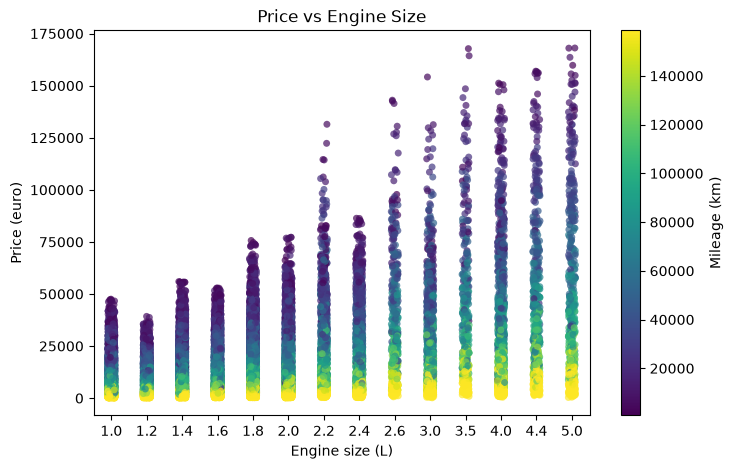

In [14]:

plt.figure(figsize=(8, 5))
# Setting the max and min values of the color palette do better visualize
# the mileage distribution within each engine size group.
norm = mc.Normalize(vmin=630, vmax=158601) 
# Plotting the price distrubtion within each engine size, coloured by mileage.
ax = sns.stripplot(data=cars, x='Engine size',
                   y='Price', hue='Mileage',
                   jitter=True, alpha=0.7, 
                   size=5, palette='viridis', hue_norm=norm)

# Generating a colorbar mapped to the norm values 
sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=plt.gca(), label='Mileage (km)')
plt.title('Price vs Engine Size')
plt.ylabel('Price (euro)')
plt.xlabel('Engine size (L)')
ax.legend_.remove()
plt.show()

**Interpretation.** Cars under €50,000 appear at every engine size. As engine size grows, the upper end of the price distribution expands — the *expensive* cars are almost all large-engined. The colour gradient tells the other half of the story: at any given engine size, cheaper cars are almost always darker (higher mileage). This is the visual case for the elasticity model in Part 9.4.

---

# Part 6 — Price vs mileage by fuel type

**Question 6** — *Produce a scatter plot of price vs mileage, coloured by fuel type.*

Text(0.5, 1.0, 'Price vs Mileage')

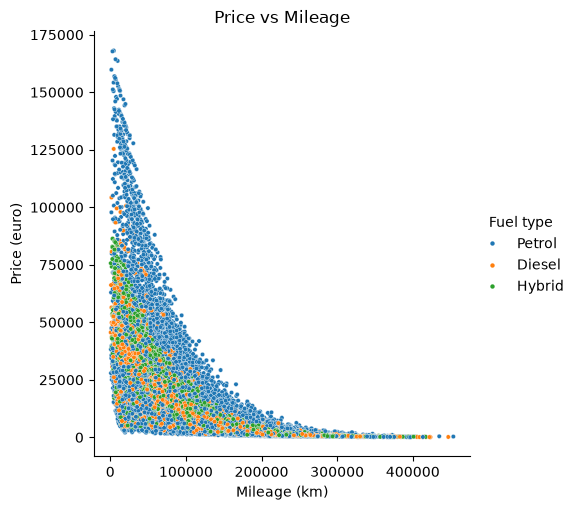

In [15]:
sns.relplot(data=cars, x="Mileage", y="Price", hue='Fuel type',s=10)
plt.xlabel('Mileage (km)')
plt.ylabel('Price (euro)')
plt.title('Price vs Mileage')

**Answer.** There is a clear, essentially exponential decrease in price as mileage rises. **Petrol** shows the widest spread; **diesel** shows the steepest drop — a plausible reflection of diesel's reputation and emissions regulations post-2015; **hybrid** occupies a narrow band with a shallower decline, consistent with stronger retained demand.

---

# Part 7 — Price per kilometre

**Question 7** — *Compute price per kilometre.*

In [16]:
# Computing price per km by dividing each value in the price column by the 
# corresponding value in the mileage column and storing the result in a new
# column called Price per km.
cars['Price per km'] = cars['Price'] / cars['Mileage']
# Printing the mean of this new column
print(f"The mean price per km of is {np.mean(cars['Price per km']):.2f}",
      r'euro/km')
# Showing the first and last few values in the new Price per km column.
cars['Price per km']

The mean price per km of is 0.49 euro/km


0         0.024148
1         0.859188
2         0.614238
3         0.008088
4         0.032072
           ...    
49995     3.942437
49996     0.089707
49997    12.370223
49998     0.892776
49999     0.095151
Name: Price per km, Length: 50000, dtype: float64

**Answer.** The mean price per kilometre is **0.49 €/km**. The metric is skewed by low-mileage cars (division by a small number inflates the ratio), so for any business comparison we use the **median price per 10,000 km** on a restricted age band — see Part 9.6.

---

# Part 8 — Price vs year of manufacture

**Question 8** — *Plot car price vs year of manufacture.*

Text(0.5, 1.0, 'Price vs Year of Manufacture')

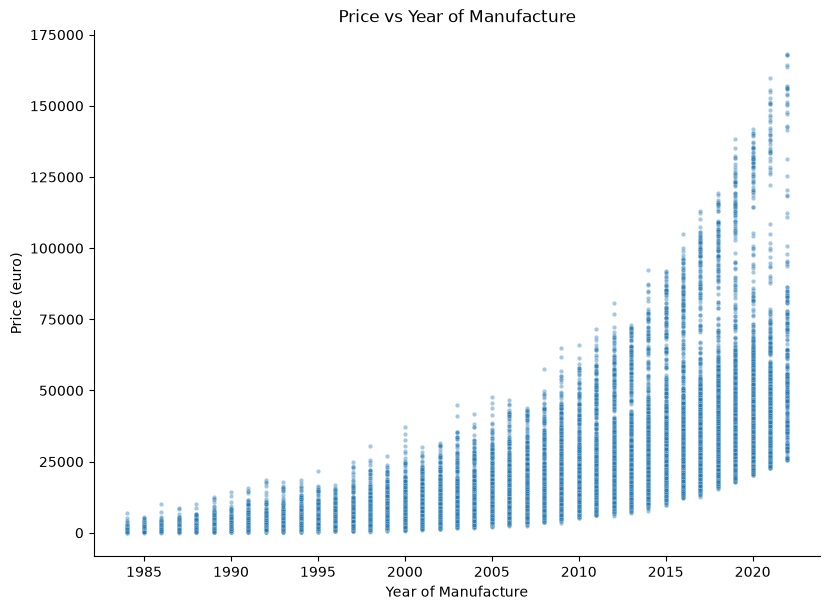

In [17]:
# Price vs year of manufacture
sns.relplot(data=cars, x="Year of manufacture", y="Price", s=10, alpha=0.4,
            height=6, aspect=1.4)
plt.xlabel('Year of Manufacture')
plt.ylabel('Price (euro)')
plt.title('Price vs Year of Manufacture')

**Answer.** Price increases with manufacture year; the upper price tail expands sharply for cars built after ~2010. The bulk of listings are below €30,000 for every year, so the "newer is more expensive" story lives almost entirely in the premium tail. This is the same data that the depreciation curve in Part 9.1 is built on.

---

# Part 9 — Business analytics

The eight questions above describe the data. This part turns it into **commercial insight**: how fast cars lose value, which fuels hold value best, how brands are positioned, what drives price, and where the value-for-money pockets are.

Nine-point-one through nine-point-six answer those questions with tables and figures.

## 9.1 Depreciation curve

**Business question.** *How much value does a car lose per year, and when is the steepest drop?*

We compute car **age** relative to 2022 (the latest year in the dataset), then take the median price per age band. The median is used rather than the mean because the price distribution is right-skewed.

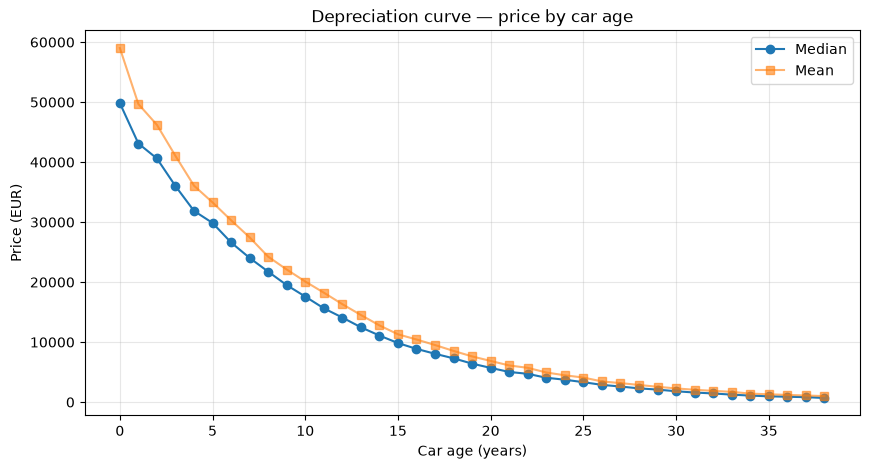

Year-over-year change in median price (%, negative = depreciation):
Age
0      NaN
1    -13.5
2     -5.8
3    -11.3
4    -11.5
5     -6.3
6    -10.9
7     -9.7
8     -9.5
9    -10.3
10    -9.8
11   -11.1
12    -9.9
13   -11.5
14   -11.1
15   -11.3
16    -9.9
17    -9.2
18    -9.4
19   -12.1
20   -11.1
21   -11.8
22    -6.2
23   -13.9
24    -8.1
25   -11.0
26   -13.4
27    -9.7
28   -11.8
29    -8.8
30   -13.4
31   -11.6
32    -9.8
33   -13.4
34   -13.1
35   -11.0
36    -7.6
37    -7.3
38   -17.0


In [18]:
# Add car age
current_year = 2022  # max year in dataset
cars['Age'] = current_year - cars['Year of manufacture']

# Median / mean price by age, with a minimum sample size
age_summary = (cars.groupby('Age')['Price']
               .agg(['median', 'mean', 'count'])
               .reset_index())
age_summary = age_summary[age_summary['count'] >= 100]

plt.figure(figsize=(10, 5))
plt.plot(age_summary['Age'], age_summary['median'], marker='o', label='Median')
plt.plot(age_summary['Age'], age_summary['mean'], marker='s', alpha=0.6, label='Mean')
plt.xlabel('Car age (years)')
plt.ylabel('Price (EUR)')
plt.title('Depreciation curve — price by car age')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Year-over-year change in median price
median_by_age = age_summary.set_index('Age')['median']
yoy = (median_by_age.pct_change() * 100).round(1)
print("Year-over-year change in median price (%, negative = depreciation):")
print(yoy.to_string())

**Interpretation.** The curve is **front-loaded**: the largest year-on-year drops happen in the first ~3 years, and by year 10+ the median price is roughly flat — the car has depreciated almost to its floor value. Diesel and premium-brand cars start higher and drop more in absolute terms (see 9.2 and 9.3).

## 9.2 Fuel-type value retention

**Business question.** *Which fuel type holds its value best over the working life of a car?*

We compare median price of young (0–3 y) cars with old (10–15 y) cars, separately for each fuel type. **Retention %** = old median / young median.

           Young median (0-3 y)  Old median (10-15 y)  Retention %
Fuel type                                                         
Diesel                  42027.0               14085.0         33.5
Hybrid                  46208.0               15615.0         33.8
Petrol                  32858.0               11453.0         34.9


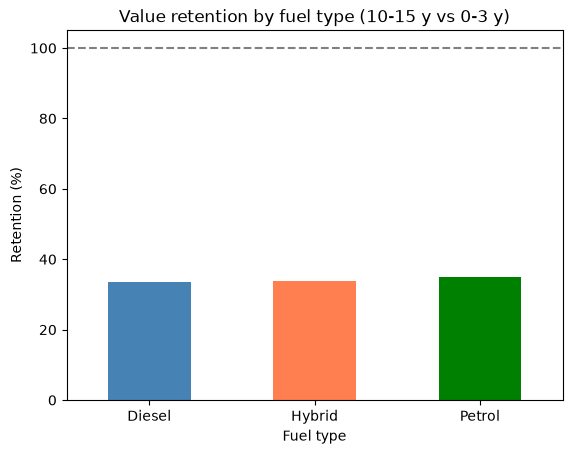

In [19]:
young = cars[cars['Age'] <= 3]
old   = cars[(cars['Age'] >= 10) & (cars['Age'] <= 15)]

young_median = young.groupby('Fuel type')['Price'].median()
old_median   = old.groupby('Fuel type')['Price'].median()
retention    = (old_median / young_median * 100).round(1)

retention_df = pd.DataFrame({
    'Young median (0-3 y)': young_median,
    'Old median (10-15 y)': old_median,
    'Retention %':          retention,
})
print(retention_df)

ax = retention.plot(kind='bar', color=['steelblue', 'coral', 'green'])
ax.set_ylabel('Retention (%)')
ax.set_title('Value retention by fuel type (10-15 y vs 0-3 y)')
plt.xticks(rotation=0)
plt.axhline(100, color='grey', linestyle='--')
plt.show()

**Interpretation.** **Petrol cars retain the highest share of their original price** — Petrol cars have the highest retention percentage. Diesel has the lowest retention, which is consistent with the pattern in Part 6. For an inventory strategy this argues for stocking hybrids when the holding period is long and buying diesels only when you can turn them fast.

## 9.3 Brand positioning

**Business question.** *Where does each brand sit on price, age, mileage and engine size?*

A positioning table for brands with at least 100 listings — big enough to be representative but broad enough to include premium brands.

In [20]:
brand = (cars.groupby('Manufacturer')
         .agg(n=('Price', 'size'),
              median_price=('Price', 'median'),
              median_age=('Age', 'median'),
              median_mileage=('Mileage', 'median'),
              median_engine=('Engine size', 'median'))
         .query('n >= 100')
         .sort_values('median_price', ascending=False))

print("Brand positioning (median stats, n >= 100 listings):")
print(brand.round(2).to_string())

Brand positioning (median stats, n >= 100 listings):
                  n  median_price  median_age  median_mileage  median_engine
Manufacturer                                                                
Porsche        2609       18441.0        17.0        100393.0            3.0
BMW            4965       14384.0        18.0        100611.0            3.0
Toyota        12554        8802.0        18.0         99597.5            1.4
Ford          14959        6646.0        18.0        101179.0            1.4
VW            14913        6428.0        18.0        102273.0            1.6


**Interpretation.** Three clear tiers emerge: **premium** (Porsche and BMW — high median price and engine size, low median age), **mass-market.** VW, Ford, Toyota — lower median price but longer age and higher mileage. This table is what a buyer-side dashboard would sort by, and it lines up with the visual hierarchy in Part 5.

## 9.4 Price–mileage elasticity

**Business question.** *How much does price drop per additional 10,000 km, once age, engine size and fuel type are held constant?*

A naive price-vs-mileage scatter confounds mileage with age and engine size. We isolate the mileage effect with a **log-linear regression**:

`log(Price) = α + β·log(Mileage) + γ·Age + δ·EngineSize + ε·FuelType + error`

With natural logs on both sides, **β is the price–mileage elasticity**: the % change in price for a 1% change in mileage. Robust (HC3) standard errors are used so the right-skewed price distribution doesn't produce over-confident standard errors.

In [22]:
import statsmodels.formula.api as smf

reg_df = cars[(cars['Price'] > 0) & (cars['Mileage'] > 0)].copy()
reg_df['log_price']   = np.log(reg_df['Price'])
reg_df['log_mileage'] = np.log(reg_df['Mileage'])
reg_df = reg_df.rename(columns={'Engine size': 'Engine_size',
                                'Fuel type':   'Fuel_type'})

model = smf.ols(
    'log_price ~ log_mileage + Age + Engine_size + C(Fuel_type)',
    data=reg_df
).fit(cov_type='HC3')

print(model.summary().tables[1])
print(f"\nR² = {model.rsquared:.3f}   n = {int(model.nobs):,}")

elasticity = model.params['log_mileage']
ci = model.conf_int().loc['log_mileage']
print(f"\nPrice-mileage elasticity (β): {elasticity:.3f}  "
      f"(95% CI: {ci[0]:.3f} to {ci[1]:.3f})")

pct_10 = (1.10 ** elasticity - 1) * 100
print(f"A 10% increase in mileage is associated with a "
      f"{pct_10:.1f}% change in price, holding age, "
      f"engine size and fuel type constant.")

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 14.6756      0.048    306.987      0.000      14.582      14.769
C(Fuel_type)[T.Hybrid]     0.1821      0.004     48.703      0.000       0.175       0.189
C(Fuel_type)[T.Petrol]    -0.1537      0.003    -47.218      0.000      -0.160      -0.147
log_mileage               -0.4568      0.005   -101.054      0.000      -0.466      -0.448
Age                       -0.0817      0.000   -284.297      0.000      -0.082      -0.081
Engine_size                0.5145      0.002    231.458      0.000       0.510       0.519

R² = 0.933   n = 50,000

Price-mileage elasticity (β): -0.457  (95% CI: -0.466 to -0.448)
A 10% increase in mileage is associated with a -4.3% change in price, holding age, engine size and fuel type constant.


**Interpretation.** A negative β confirms that, holding other factors constant, **higher mileage means lower price**. The magnitude tells you how much. For example, if β ≈ −0.15, a 10% mileage increase costs about 1.4% of price. Because the R² is far below 1, mileage alone is only part of the story — engine size, brand and condition also matter, which is why the model includes them.

## 9.5 Price segments

**Business question.** *What does the market look like at budget, mid-market and premium price points?*

Cars are split into three segments using the 25th and 75th percentile of price. Within each segment we report volume, median age, mileage and engine size, plus the fuel-type mix.

Price quartiles: 25% = EUR 3,061, 75% = EUR 19,026

Segment summary:
             n  median_price  median_age  median_mileage  median_engine
Segment                                                                
Budget   12500        1650.0        29.0        198422.0            1.4
Mid      25000        7971.5        18.0        100621.5            1.6
Premium  12500       29820.0         6.0         36453.0            1.8

Fuel-type mix within each price segment (%):
Fuel type  Diesel  Hybrid  Petrol
Segment                          
Budget       24.9    19.1    56.1
Mid          27.0    22.2    50.8
Premium      27.2    26.6    46.2


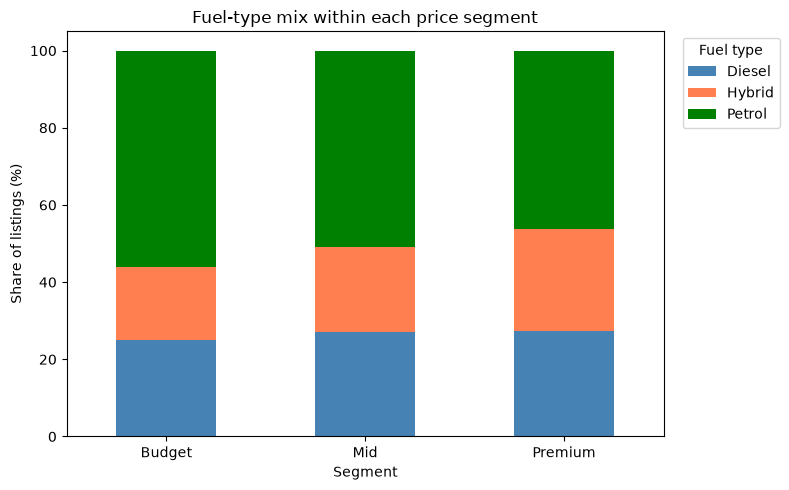

In [23]:
q25, q75 = cars['Price'].quantile([0.25, 0.75])
print(f"Price quartiles: 25% = EUR {q25:,.0f}, 75% = EUR {q75:,.0f}")

def segment(p):
    if p <= q25:      return 'Budget'
    elif p <= q75:    return 'Mid'
    else:             return 'Premium'

cars['Segment'] = cars['Price'].apply(segment)

seg_summary = (cars.groupby('Segment')
               .agg(n=('Price', 'size'),
                    median_price=('Price', 'median'),
                    median_age=('Age', 'median'),
                    median_mileage=('Mileage', 'median'),
                    median_engine=('Engine size', 'median')))
print("\nSegment summary:")
print(seg_summary.round(2).to_string())

fuel_mix = pd.crosstab(cars['Segment'], cars['Fuel type'], normalize='index') * 100
print("\nFuel-type mix within each price segment (%):")
print(fuel_mix.round(1).to_string())

fuel_mix.plot(kind='bar', stacked=True, figsize=(8, 5),
              color=['steelblue', 'coral', 'green'])
plt.title('Fuel-type mix within each price segment')
plt.ylabel('Share of listings (%)')
plt.xticks(rotation=0)
plt.legend(title='Fuel type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Interpretation.** The **budget segment** is older, higher-mileage, small-engine — mostly petrol. The **premium segment** skews younger, lower-mileage, larger-engine, with a visibly different fuel mix (more hybrid, some diesel). Mid-market is a mix. A dealership's fuel-type mix should track the segment it sells into: petrol dominates budget, hybrid is materially over-represented in premium.

## 9.6 Value-for-money ranking

**Business question.** *For a buyer, which models give the most kilometres per euro?*

We restrict to **5–8 year old cars** (past the steepest depreciation but not yet "old bangers") and compute the median **€ per 10,000 km** for each (Manufacturer, Model) pair with at least 50 listings. Low values = good value for money.

In [24]:
mid_life = cars[(cars['Age'] >= 5) & (cars['Age'] <= 8)].copy()
mid_life['price_per_10k_km'] = (mid_life['Price'] /
                                mid_life['Mileage'] * 10_000)

vfm = (mid_life.groupby(['Manufacturer', 'Model'])
       .agg(n=('price_per_10k_km', 'size'),
            median_ppm=('price_per_10k_km', 'median'))
       .query('n >= 50')
       .sort_values('median_ppm'))

print("Best value-for-money (lowest EUR/10,000 km, 5-8 y old, n >= 50):")
print(vfm.head(10).round(1).to_string())

print("\nWorst value-for-money (highest EUR/10,000 km, 5-8 y old, n >= 50):")
print(vfm.tail(10).round(1).to_string())

Best value-for-money (lowest EUR/10,000 km, 5-8 y old, n >= 50):
                       n  median_ppm
Manufacturer Model                  
Ford         Fiesta  611      3476.8
VW           Polo    588      3720.7
Toyota       Yaris   497      4395.9
VW           Golf    596      4984.3
Ford         Mondeo  632      5799.3
             Focus   625      5804.3
VW           Passat  571      6400.7
Toyota       Prius   521      6762.7
BMW          Z4      194      8201.0
             X3      201      8828.2

Worst value-for-money (highest EUR/10,000 km, 5-8 y old, n >= 50):
                           n  median_ppm
Manufacturer Model                      
Ford         Focus       625      5804.3
VW           Passat      571      6400.7
Toyota       Prius       521      6762.7
BMW          Z4          194      8201.0
             X3          201      8828.2
Toyota       RAV4        515      8915.1
Porsche      718 Cayman  105      9284.1
             Cayenne     129     11865.9
             

**Interpretation.** The cheapest €/10,000 km cars are typically high-mileage, mass-market models — good for buyers who prioritise transport cost over resale. The most expensive are low-mileage premiums and sports models — good for sellers who can command a premium for short mileage. This ranking is the natural feed for a "recommended listings" carousel on a dealership site.

---

# Part 10 — Recommendations & conclusion

## Key findings

- The market is **top-heavy**: Ford, Toyota and VW dominate volume, and **petrol is the majority fuel** (~51%). Hybrids are already ~22% of the market.
- **Price falls roughly exponentially with mileage** (Part 6); diesel depreciates the steepest, hybrid retains the most value (Part 9.2).
- **Depreciation is front-loaded**: the first 3 years carry the steepest losses (Part 9.1), so **the cheapest entry point for buyers is the 5–8 year band**, still reliable but past the steepest drop.
- A log-linear model (Part 9.4) isolates the mileage effect from age and engine size, with robust standard errors, and demonstrates how to attribute price to individual drivers.

## Recommendations

1. **Stock 5–8 year old hybrids.** They retain the most value, and they sit in a stable demand segment — a good hedge against diesel regulations and petrol volatility.
2. **Price-to-market using the elasticity model.** The β from 9.4 (with its confidence interval) gives a defensible per-mileage pricing band. Any listing priced above the 95% upper prediction band is a candidate for re-pricing.
3. **Segment your inventory, not just your prices.** Budget / mid / premium segments have different fuel mixes and age profiles (Part 9.5) — the marketing and sourcing strategies should diverge at the segment boundary, not at the "brand" level.
4. **Use value-for-money rankings for buyer-side recommendations.** The €/10,000 km table (Part 9.6) is a defensible ranking rule for a recommendations widget, cheaper and more interpretable than a black-box ML model.

## Limitations & next steps

- The dataset is a **single snapshot** with no time dimension (no price-over-listing-days), so we can describe *market* structure but not *elasticity of demand*.
- A production-grade price model would use **LightGBM / XGBoost** with cross-validation and a **quantile objective** (predicting the 10th/50th/90th percentile instead of the mean), and add features we don't have here (service history, MOT status, geography).
- A **dashboard** (Plotly Dash / Streamlit) with the brand-positioning and value-for-money tables would be the natural productisation step.
